# Yeast Panoptic Segmentation Demo

Loads the trained Panoptic-DeepLab model, runs it on a sample image, and displays the predicted panoptic segmentation mask.

## Setup

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('./detectron2'))
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('./projects/Panoptic-DeepLab/'))
os.environ['DETECTRON2_DATASETS'] = '/home/liwa/data/datasets/'

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from skimage.io import imread

from detectron2.config import get_cfg
from detectron2.data import MetadataCatalog
from detectron2.projects.panoptic_deeplab import add_panoptic_deeplab_config
from detectron2.structures import Instances
from detectron2.utils.visualizer import Visualizer

from run_notebooks.post_process_utils import convert_to_rgb
from prediction import Predictor


def show_image(img, title=None):
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def resize_long_side(image, target):
    """Resize `image` so its longer side equals `target`, keeping aspect ratio."""
    h, w = image.shape[:2]
    scale = target / max(h, w)
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(image, (new_w, new_h), interpolation=interp)


def resize_panoptic_seg(panoptic_seg, orig_size):
    """Nearest-neighbor resize a panoptic label map back to `orig_size` (H, W)."""
    arr = panoptic_seg.to("cpu").numpy()
    orig_h, orig_w = orig_size
    resized = cv2.resize(arr.astype(np.int32), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    return torch.as_tensor(resized.astype(np.int64))


def resize_instances(instances, orig_size):
    """Scale an Instances object's boxes/masks from its current image_size up to `orig_size`."""
    instances = instances.to("cpu")
    orig_h, orig_w = orig_size
    cur_h, cur_w = instances.image_size
    scale_x, scale_y = orig_w / cur_w, orig_h / cur_h

    new_instances = Instances((orig_h, orig_w))
    if instances.has("scores"):
        new_instances.scores = instances.scores
    if instances.has("pred_classes"):
        new_instances.pred_classes = instances.pred_classes
    if instances.has("pred_boxes"):
        boxes = instances.pred_boxes.clone()
        boxes.scale(scale_x, scale_y)
        new_instances.pred_boxes = boxes
    if instances.has("pred_masks"):
        masks = instances.pred_masks.numpy()
        if len(masks):
            resized_masks = np.stack([
                cv2.resize(m.astype(np.uint8), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST).astype(bool)
                for m in masks
            ])
        else:
            resized_masks = np.zeros((0, orig_h, orig_w), dtype=bool)
        new_instances.pred_masks = torch.as_tensor(resized_masks)
    return new_instances


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Build the predictor

In [2]:
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
cfg.merge_from_file("/home/liwa/data/PytrochDeepyeast/projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml")
cfg.MODEL.DEVICE = "cuda"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3
cfg.MODEL.WEIGHTS = os.path.abspath("/home/liwa/data/oneformer_output/output/model_0159999_v2.pth")

predictor = Predictor(cfg)


Some model parameters or buffers are not found in the checkpoint:
sem_seg_head.loss.criterion.weight


## Load and show the input image

Resized (2040, 2040) -> (1024, 1024) for inference


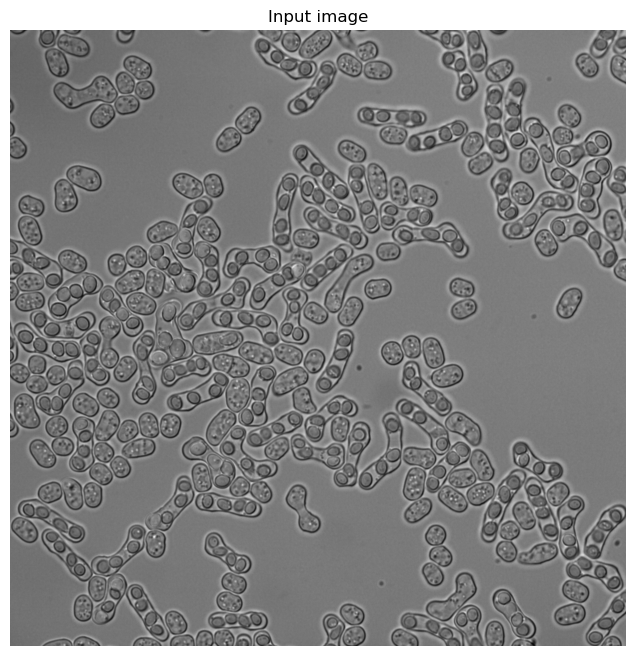

In [3]:
image_path = "./YeastPanoptic_samples/00001_leftImg8bit.png"
infer_size = 1024  # longer side in pixels for inference; set to None to predict at full resolution

im = imread(image_path)
image = convert_to_rgb(im)
orig_size = image.shape[:2]

if infer_size and max(orig_size) > infer_size:
    infer_image = resize_long_side(image, infer_size)
    print(f"Resized {orig_size} -> {infer_image.shape[:2]} for inference")
else:
    infer_image = image

show_image(image, title="Input image")


## Run prediction

In [4]:
prediction_output = predictor(infer_image)
instances = prediction_output["instances"]
panoptic_seg, _ = prediction_output["panoptic_seg"]

if infer_image.shape[:2] != orig_size:
    panoptic_seg = resize_panoptic_seg(panoptic_seg, orig_size)
    instances = resize_instances(instances, orig_size)

scores = [1] + list(instances.scores.to("cpu"))

segments_info = []
for i, panoptic_label in enumerate(np.unique(panoptic_seg.to("cpu").numpy())[1:]):
    if panoptic_label == -1:
        # VOID region
        continue
    segments_info.append({
        "id": int(panoptic_label),
        "category_id": int(panoptic_label // 1000),
        "isthing": i != 0,
        "score": float(scores[i]),
    })


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/torch/functional.py:445: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at  /opt/conda/conda-bld/pytorch_1639180588308/work/aten/src/ATen/native/TensorShape.cpp:2157.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


## Show the panoptic segmentation mask

{0: {'id': 0, 'category_id': 0, 'isthing': False, 'score': 1.0}, 1001: {'id': 1001, 'category_id': 1, 'isthing': True, 'score': 0.9936853647232056}, 1002: {'id': 1002, 'category_id': 1, 'isthing': True, 'score': 0.9762803316116333}, 1003: {'id': 1003, 'category_id': 1, 'isthing': True, 'score': 0.9766680598258972}, 1004: {'id': 1004, 'category_id': 1, 'isthing': True, 'score': 0.9300437569618225}, 1005: {'id': 1005, 'category_id': 1, 'isthing': True, 'score': 0.46916401386260986}, 1006: {'id': 1006, 'category_id': 1, 'isthing': True, 'score': 1.0018781423568726}, 1007: {'id': 1007, 'category_id': 1, 'isthing': True, 'score': 0.9779390096664429}, 1008: {'id': 1008, 'category_id': 1, 'isthing': True, 'score': 0.9839896559715271}, 1009: {'id': 1009, 'category_id': 1, 'isthing': True, 'score': 0.9822518825531006}, 1010: {'id': 1010, 'category_id': 1, 'isthing': True, 'score': 0.9686861634254456}, 1011: {'id': 1011, 'category_id': 1, 'isthing': True, 'score': 0.9920275807380676}, 1012: {'id

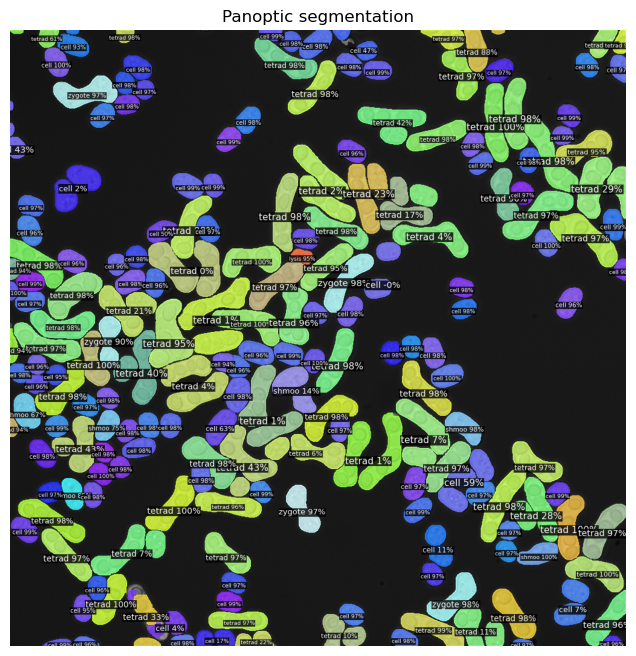

In [5]:
v = Visualizer(image[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.5)
out = v.draw_panoptic_seg(panoptic_seg.to("cpu"), segments_info, area_threshold=20.0, alpha=0.8)
show_image(out.get_image()[:, :, ::-1], title="Panoptic segmentation")


## Show instance predictions

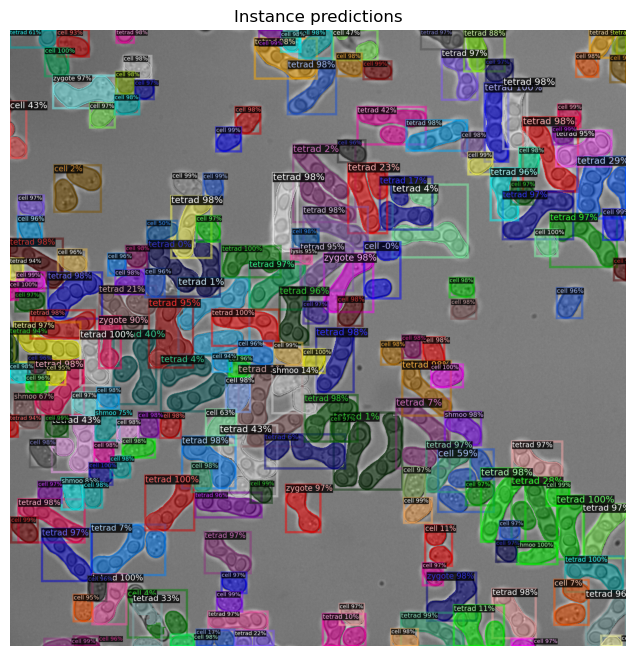

In [6]:
v = Visualizer(image[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1)
out = v.draw_instance_predictions(instances.to("cpu"), segments_info)
show_image(out.get_image()[:, :, ::-1], title="Instance predictions")
